# Lab Day 10: Finetune Qwen3-VL-4B (LoRA) để định vị hư hại mặt đường — bản chạy trên Kaggle

Notebook này chỉ **điều phối**: mã thật nằm trong package `d10/` của repo (mỗi thí nghiệm chạy thành một tiến trình riêng để GPU được giải phóng hoàn toàn giữa các lần chạy). Công cụ của đề trong `scripts/` và `tests/` không bị sửa.

**Trước khi chạy**

1. Push repo lên GitHub (repo công khai), rồi sửa `REPO_URL` ở ô đầu nếu cần.
2. Kaggle → *Settings*: **Accelerator = GPU T4 x2**, **Internet = On**.
3. Dữ liệu: không cần làm gì, notebook tự tải zip công khai của dataset `lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes` (hoặc dùng bản đã gắn qua *Add Input* nếu có).
4. (Tuỳ chọn) *Add-ons → Secrets*: `HF_TOKEN` để tải model nhanh hơn. Không dán khoá vào notebook.

**Cách chạy:** *Save Version → Save & Run All (Commit)* để chạy nền, hoặc *Run All* trong phiên tương tác. Mọi bước đều bỏ qua phần đã có kết quả, nên chạy lại sau khi lỗi sẽ tiếp tục từ chỗ dở (trong cùng một phiên).

**Kết quả:** ô cuối đóng gói `report/` (evidence, log, ảnh minh hoạ, output thô) thành `/kaggle/working/day10_results.zip`. Tải về, giải nén vào thư mục gốc của repo rồi commit.

## 0. Môi trường (Kaggle T4)

In [ ]:
REPO_URL = "https://github.com/hddung-vinai/K4-Track-4-Day10-VisionLanguageModel.git"
BRANCH = "main"
RUN_SMOKE = True   # chạy thử toàn pipeline 2 bước / 8 ảnh trước khi chạy thật
RUN_E5 = True      # bonus GRPO (tuỳ chọn)

import os
ROOT = "/kaggle/working/lab"
if not os.path.isdir(f"{ROOT}/.git"):
    !git clone -q -b $BRANCH $REPO_URL $ROOT
%cd $ROOT
!git pull -q --ff-only
!git log --oneline -1
assert os.path.isdir("d10") and os.path.isdir("tests_d10"), (
    "Repo trên GitHub chưa có thư mục d10/: commit + push code ở máy lên nhánh " + BRANCH + " rồi chạy lại")
!nvidia-smi -L
!pip -q install -r requirements-colab.txt

/kaggle/working/lab
31d5b31 (HEAD -> main, origin/main, origin/HEAD) fix: bỏ qua torchao không tương thích của Kaggle khi gắn LoRA lên ViT; chạy thử E5 trước
GPU 0: Tesla T4 (UUID: GPU-61b2e988-83cb-416a-73ab-613b436ffdbc)
GPU 1: Tesla T4 (UUID: GPU-9a752a0f-5866-d903-f746-4c6d6918186b)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 89.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 35.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 889.0/889.0 kB 38.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.3/394.3 kB 17.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 48.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 27.9 MB/s eta 0:00:00


In [2]:
# HF_TOKEN là tuỳ chọn và chỉ đọc từ Kaggle Secrets. KHÔNG viết khoá vào notebook.
try:
    from kaggle_secrets import UserSecretsClient
    os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("HF_TOKEN")
    print("HF_TOKEN: lấy từ Kaggle Secrets")
except Exception:
    print("Không có secret HF_TOKEN: tải model ẩn danh")

Không có secret HF_TOKEN: tải model ẩn danh


## 1. Dữ liệu: tải và chia split

In [3]:
import glob
SLUG = "lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes"
hits = glob.glob("/kaggle/input/**/labels-YOLO", recursive=True)
if hits:                                   # dataset đã gắn qua Add Input
    SRC = os.path.dirname(hits[0])
    print("nguồn dữ liệu:", SRC)
    !python scripts/prepare_data.py --source "$SRC"
else:
    # Dataset công khai (MIT): tải zip thẳng từ API của Kaggle, không cần khoá và không cần Add Input.
    ZIP_URL = f"https://www.kaggle.com/api/v1/datasets/download/{SLUG}"
    print("nguồn dữ liệu:", ZIP_URL)
    !python scripts/prepare_data.py --zip "$ZIP_URL"
assert _exit_code == 0, "prepare_data.py lỗi"

nguồn dữ liệu: /kaggle/input/datasets/lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes/data
dataset_version : d10-21e4070301
  train  1422 ảnh  boxes={'pothole': 1074, 'crack': 1750, 'manhole': 691}
  val     276 ảnh  boxes={'pothole': 66, 'crack': 470, 'manhole': 103}
  test    311 ảnh  boxes={'pothole': 121, 'crack': 299, 'manhole': 163}


In [4]:
# Công cụ của đề + test của phần mã tự viết (nhãn, reward)
!python -m pytest -q
!python -m pytest -q tests_d10

...........................s.........................................    [100%]
68 passed, 1 skipped in 0.34s
...................                                                      [100%]
19 passed in 7.52s


In [5]:
import json
from collections import Counter
from scripts.labcommon import read_jsonl

splits = {s: read_jsonl(f"data/splits/{s}.jsonl") for s in ("train", "val", "test")}
for s, rows in splits.items():
    c = Counter(o["label"] for r in rows for o in r["objects"])
    print(f"{s:5s} {len(rows):5d} ảnh  {sum(c.values()):5d} box  {dict(c)}  "
          f"ảnh không có box: {sum(not r['objects'] for r in rows)}")

# Không phiên quay nào được nằm ở hai split (chống rò rỉ giữa các frame liền kề)
sess = {s: {r["session"] for r in rows} for s, rows in splits.items()}
assert not (sess["train"] & sess["val"] or sess["train"] & sess["test"] or sess["val"] & sess["test"])
print({s: len(v) for s, v in sess.items()}, "phiên; không phiên nào trùng giữa các split")
print("dataset_version:", json.load(open("data/splits/meta.json"))["dataset_version"])

train  1422 ảnh   3515 box  {'manhole': 691, 'pothole': 1074, 'crack': 1750}  ảnh không có box: 0
val     276 ảnh    639 box  {'crack': 470, 'manhole': 103, 'pothole': 66}  ảnh không có box: 0
test    311 ảnh    583 box  {'crack': 299, 'manhole': 163, 'pothole': 121}  ảnh không có box: 0
{'train': 13, 'val': 2, 'test': 3} phiên; không phiên nào trùng giữa các split
dataset_version: d10-21e4070301


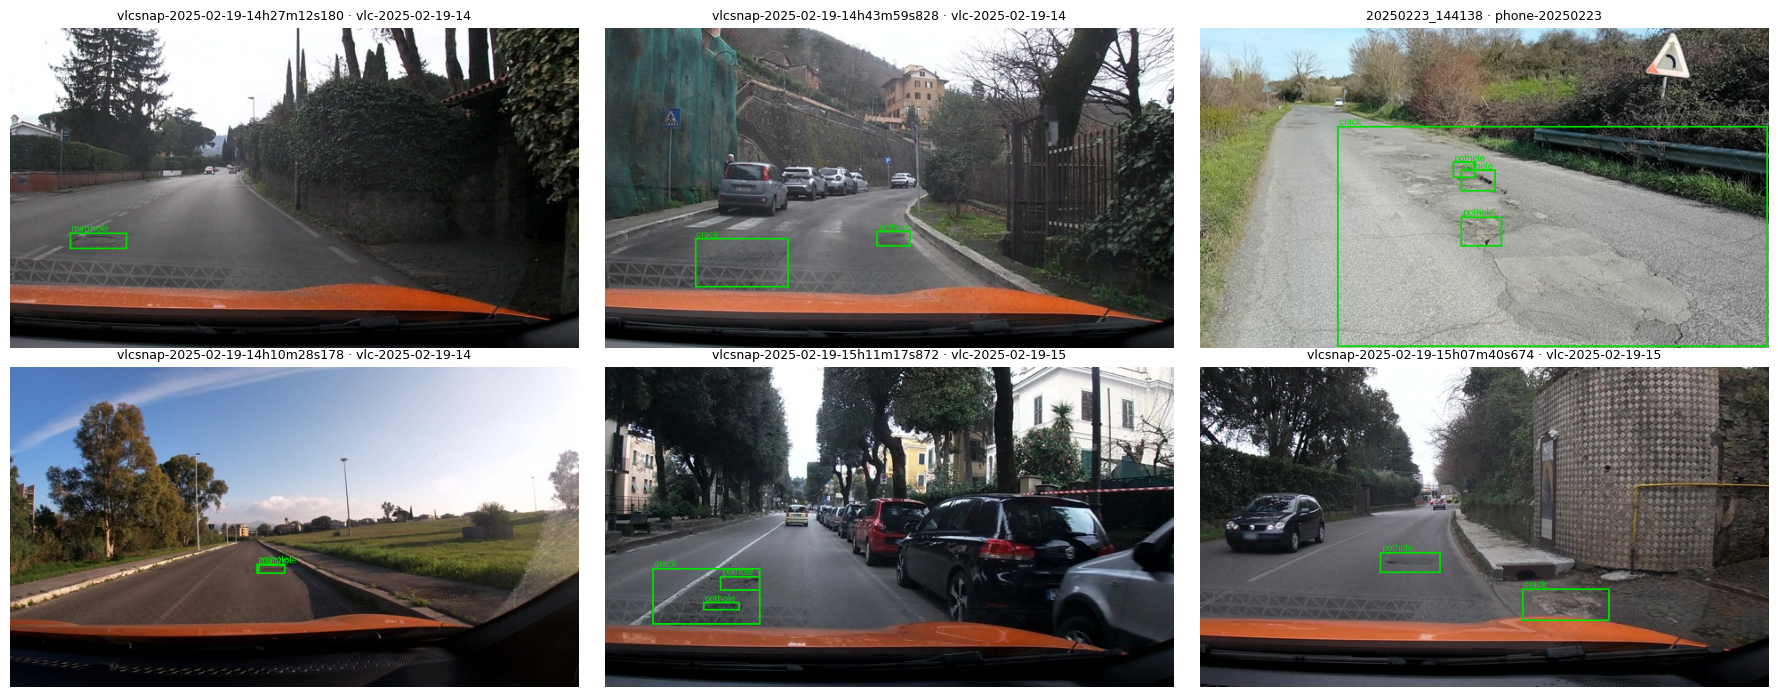

In [6]:
# 6 ảnh train có box. Box vẽ từ nhãn SAU khi đổi sang thang 0-1000 (bước 2),
# nên nếu phép đổi sai thì box sẽ lệch khỏi vật thể ngay ở đây.
import random
import matplotlib.pyplot as plt
from PIL import Image
from d10.viz import draw, gt_as_seen_by_model

sample = random.Random(0).sample([r for r in splits["train"] if r["objects"]], 6)
fig, axes = plt.subplots(2, 3, figsize=(18, 7))
for ax, r in zip(axes.flat, sample):
    ax.imshow(draw(Image.open(f"data/{r['image_path']}"), gt=gt_as_seen_by_model(r)))
    ax.set_title(f"{r['image_id']} · {r['session']}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 2. Nhãn: YOLO → JSON thang 0–1000

In [7]:
import inspect
from d10 import labels

print(inspect.getsource(labels.yolo_to_box))
print(inspect.getsource(labels.objects_to_answer))
print("PROMPT:", labels.PROMPT)

def yolo_to_box(label, yolo):
    """One YOLO box [xc, yc, w, h] in [0,1] -> {"label", "bbox_2d": [x1, y1, x2, y2]} in 0-1000."""
    xc, yc, w, h = yolo
    raw = ((xc - w / 2), (yc - h / 2), (xc + w / 2), (yc + h / 2))
    x1, y1, x2, y2 = (min(max(int(round(v * SCALE)), 0), SCALE) for v in raw)
    # A very thin box can collapse to zero width/height after rounding. score.py rejects the
    # WHOLE output when any box has x2 <= x1, so never teach the model a degenerate box.
    if x2 <= x1:
        x1, x2 = (x1, x1 + 1) if x1 < SCALE else (SCALE - 1, SCALE)
    if y2 <= y1:
        y1, y2 = (y1, y1 + 1) if y1 < SCALE else (SCALE - 1, SCALE)
    return {"label": label, "bbox_2d": [x1, y1, x2, y2]}

def objects_to_answer(objects):
    """All objects of one image -> the target string the model must generate ("[]" if none)."""
    boxes = [yolo_to_box(o["label"], o["yolo"]) for o in objects]
    # top-to-bottom, left-to-right: a stable order, so the same image always has the same target


In [8]:
# Kiểm tra: đổi nhãn sang JSON 0-1000 rồi quy ngược về pixel phải trùng box gốc
# (sai số chỉ do làm tròn: 0,5/1000 cạnh ảnh, tức < 0,4 px với ảnh 640x360).
# Một số nhãn YOLO có mép box vượt ra ngoài khung hình; yolo_to_box kẹp chúng vào [0, 1000],
# nên box gốc cũng được kẹp vào khung trước khi so sánh.
worst, outside = 0.0, 0
for r in splits["train"]:
    w, h = r["width"], r["height"]
    for o in r["objects"]:
        xc, yc, bw, bh = o["yolo"]
        orig = ((xc - bw / 2) * w, (yc - bh / 2) * h, (xc + bw / 2) * w, (yc + bh / 2) * h)
        clipped = (max(orig[0], 0), max(orig[1], 0), min(orig[2], w), min(orig[3], h))
        outside += clipped != orig
        back = labels.box_to_pixels(labels.yolo_to_box(o["label"], o["yolo"])["bbox_2d"], w, h)
        worst = max(worst, *(abs(a - b) for a, b in zip(clipped, back)))
print(f"sai số lớn nhất sau khi quy ngược: {worst:.3f} px | box có mép vượt khung: {outside}")
assert worst < 1.0

r = sample[0]
print("ví dụ đáp án:", labels.objects_to_answer(r["objects"]))

# Mỗi box tốn khoảng 29 token, nên max_new_tokens quyết định số box tối đa trả về được.
for s, rows in splits.items():
    n = sorted(len(r["objects"]) for r in rows)
    print(f"{s:5s} box/ảnh: trung vị {n[len(n) // 2]}, p99 {n[int(0.99 * len(n))]}, max {n[-1]}, "
          f"ảnh > 8 box: {sum(x > 8 for x in n)}")

sai số lớn nhất sau khi quy ngược: 0.320 px | box có mép vượt khung: 49
ví dụ đáp án: [{"label":"manhole","bbox_2d":[105,639,205,689]}]
train box/ảnh: trung vị 2, p99 8, max 13, ảnh > 8 box: 9
val   box/ảnh: trung vị 2, p99 6, max 9, ảnh > 8 box: 1
test  box/ảnh: trung vị 1, p99 5, max 7, ảnh > 8 box: 0


## 3. E0: zero-shot

In [9]:
# Chạy thử toàn bộ pipeline (2 bước huấn luyện, 8 ảnh) để bắt lỗi môi trường trước khi chạy thật.
# Kết quả thử nằm ở work/smoke/, KHÔNG ghi vào report/evidence.
if RUN_SMOKE:
    !python -m d10.pipeline e0 e1 e3 --smoke
    assert _exit_code == 0, "Chạy thử lỗi: xem log phía trên trước khi tốn giờ GPU"
    if RUN_E5:                             # bonus: lỗi ở đây chỉ tắt E5, không chặn E0-E4
        !python -m d10.pipeline e5 --smoke
        if _exit_code != 0:
            print("CẢNH BÁO: chạy thử E5 (GRPO) lỗi -> bỏ qua E5 trong lần chạy này")
            RUN_E5 = False


===== E0 (smoke) =====

$ /usr/bin/python3 -m d10.infer --out work/smoke/e0.jsonl --model-id Qwen/Qwen3-VL-4B-Instruct --max-new-tokens 256 --limit 8
preprocessor_config.json: 100%|████████████████| 390/390 [00:00<00:00, 1.65MB/s]
chat_template.json: 100%|██████████████████| 5.50k/5.50k [00:00<00:00, 13.2MB/s]
config.json: 100%|█████████████████████████| 1.50k/1.50k [00:00<00:00, 5.70MB/s]
tokenizer_config.json: 100%|███████████████| 10.9k/10.9k [00:00<00:00, 33.6MB/s]
vocab.json: 100%|██████████████████████████| 2.78M/2.78M [00:00<00:00, 45.5MB/s]
merges.txt: 100%|███████████████████████████| 1.67M/1.67M [00:00<00:00, 131MB/s]
tokenizer.json: 100%|███████████████████████| 7.03M/7.03M [00:00<00:00, 153MB/s]
video_preprocessor_config.json: 100%|██████████| 385/385 [00:00<00:00, 2.27MB/s]
model.safetensors.index.json: 100%|█████████| 64.7k/64.7k [00:00<00:00, 118MB/s]
Reconstructing (incomplete total...): |            |  0.00B /  0.00B            

Fetching 2 files:   0%|               

In [10]:
# E0: model gốc 4-bit, suy luận trên test -> work/e0.jsonl -> scripts/score.py -> report/evidence/e0.json
!python -m d10.pipeline e0
assert _exit_code == 0, "E0 lỗi"


===== E0 =====

$ /usr/bin/python3 -m d10.infer --out work/e0.jsonl --model-id Qwen/Qwen3-VL-4B-Instruct --max-new-tokens 256
Loading weights: 100%|████████████████████████| 713/713 [00:07<00:00, 97.76it/s]
0 done, 311 to go -> work/e0.jsonl
  8/311  11s  last: '[{"label": "crack", "bbox_2d": [0, 676, 998, 750]}]'
  48/311  54s  last: '[{"label": "crack", "bbox_2d": [0, 300, 1000, 1000]}]'
  88/311  155s  last: '[{"label": "manhole", "bbox_2d": [455, 624, 634, 700]}]'
  128/311  276s  last: '[{"label": "manhole", "bbox_2d": [630, 638, 680, 676]}]'
  168/311  407s  last: '[{"label": "manhole", "bbox_2d": [430, 486, 475, 519]}]'
  208/311  461s  last: '[{"label": "crack", "bbox_2d": [0, 430, 998, 998]}]'
  248/311  562s  last: '[{"label": "crack", "bbox_2d": [0, 721, 875, 829]}]'
  288/311  679s  last: '[{"label": "crack", "bbox_2d": [0, 720, 998, 800]}, {"label": "crack", "bbox_2d": [0, 680,'
inference: 2.42 s/image

$ /usr/bin/python3 scripts/score.py --pred work/e0.jsonl --name E0 --

In [11]:
# 5 output thô của E0: có bọc ```json không, có chữ thừa không, toạ độ theo thang nào?
for row in read_jsonl("work/e0.jsonl")[:5]:
    print(row["image_id"], "->", repr(row["raw"][:300]))

vlcsnap-00200 -> '[{"label": "manhole", "bbox_2d": [770, 640, 843, 684]}, {"label": "manhole", "bbox_2d": [909, 786, 997, 824]}]'
vlcsnap-00201 -> '[{"label": "crack", "bbox_2d": [0, 450, 500, 500]}]'
vlcsnap-00202 -> '[{"label": "manhole", "bbox_2d": [309, 687, 399, 714]}]'
vlcsnap-00203 -> '[{"label": "crack", "bbox_2d": [0, 476, 1000, 1000]}]'
vlcsnap-00204 -> '[{"label": "manhole", "bbox_2d": [257, 624, 325, 657]}]'


## 4. Dựng dữ liệu huấn luyện: chat template và mask loss

In [12]:
from d10 import data
print(inspect.getsource(data.encode_example))
print(inspect.getsource(data.collate))

def encode_example(processor, image, answer, prompt=PROMPT):
    """Tokenise (image, prompt, answer) and build labels that are -100 everywhere except the
    answer, so the loss is computed only on what the model has to generate."""
    user = user_message(image, prompt)
    assistant = {"role": "assistant", "content": [{"type": "text", "text": answer}]}
    prompt_enc = processor.apply_chat_template([user], add_generation_prompt=True, **CHAT_KW)
    full_enc = processor.apply_chat_template([user, assistant], add_generation_prompt=False, **CHAT_KW)
    n = prompt_enc["input_ids"].shape[1]
    # The mask is only correct if the prompt is an exact prefix of the full sequence.
    if not torch.equal(full_enc["input_ids"][0, :n], prompt_enc["input_ids"][0]):
        raise ValueError("prompt tokens are not a prefix of the full sequence")
    labels = full_enc["input_ids"].clone()
    labels[:, :n] = IGNORE
    out = dict(full_enc)
    out["labels"] = labels
    return out

def collate(batch,

In [13]:
# Kiểm tra trên một ví dụ: 220 token ảnh cho ảnh 640x360, và phần có labels != -100
# phải đúng là JSON đáp án (kèm <|im_end|>).
from d10.modeling import load_config, load_processor

processor = load_processor(load_config("configs/e1.yaml")["model_id"])
r = sample[0]
answer = labels.objects_to_answer(r["objects"])
ex = data.encode_example(processor, Image.open(f"data/{r['image_path']}").convert("RGB"), answer)
n_img = int((ex["input_ids"] == processor.image_token_id).sum())
kept = ex["labels"][ex["labels"] != data.IGNORE]
print("số token ảnh      :", n_img)
print("tổng số token     :", ex["input_ids"].shape[1], "| token tính loss:", len(kept))
print("giải mã phần nhãn :", repr(processor.tokenizer.decode(kept)))
assert n_img == 220
assert processor.tokenizer.decode(kept).startswith(answer + "<|im_end|>")

số token ảnh      : 220
tổng số token     : 358 | token tính loss: 31
giải mã phần nhãn : '[{"label":"manhole","bbox_2d":[105,639,205,689]}]<|im_end|>\n'


## 5. Setup LoRA / đóng băng cho E1, E2, E3

In [14]:
# Số module khớp regex (252 cho E1/E2, 348 cho E3) được kiểm tra bằng raise ngay trong apply_setup
# và in ra ở đầu log huấn luyện của từng thí nghiệm (bước 6), cùng số tham số huấn luyện.
from d10 import modeling
print("LLM:", modeling.LLM_TARGETS)
print("ViT:", modeling.VIT_TARGETS)
print(inspect.getsource(modeling.apply_setup))
print(inspect.getsource(modeling.save_trained))

LLM: (?:.*\.)?language_model\.layers\.\d+\.(?:self_attn\.[qkvo]_proj|mlp\.(?:gate|up|down)_proj)
ViT: (?:.*\.)?visual\.blocks\.\d+\.(?:attn\.(?:qkv|proj)|mlp\.linear_fc[12])
def apply_setup(model, cfg):
    """Freeze everything, add LoRA on the LLM (E1, E2) or LLM + ViT (E3), and for E2/E3 also
    unfreeze the full projector in float32. Returns (peft_model, info)."""
    from peft import LoraConfig, get_peft_model
    ignore_incompatible_torchao()
    for p in model.parameters():
        p.requires_grad = False
    model.enable_input_require_grads()            # gradient checkpointing needs inputs with grad

    lora = cfg["lora"]
    regex, matched = lora_targets(model, lora["targets"])
    text_cfg, vis_cfg = model.config.text_config, model.config.vision_config
    expected = text_cfg.num_hidden_layers * 7 + (vis_cfg.depth * 4 if "vit" in lora["targets"] else 0)
    if len(matched) != expected:                  # 252 for E1/E2, 348 for E3 on the real model
        raise RuntimeError

## 6. Vòng huấn luyện

In [15]:
from d10 import train
print(inspect.getsource(train.lr_factor))
print(inspect.getsource(train.train))

def lr_factor(step, total):
    """Linear warmup over the first 5% of steps, then cosine decay to 0."""
    warmup = max(1, int(WARMUP_FRAC * total))
    if step < warmup:
        return (step + 1) / warmup
    return 0.5 * (1 + math.cos(math.pi * (step - warmup) / max(1, total - warmup)))

def train(cfg, out_dir, data_dir="data", num_workers=2, model=None, processor=None):
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    seed = cfg["seed"]
    random.seed(seed)
    torch.manual_seed(seed)

    rows = read_jsonl(Path(data_dir) / "splits" / "train.jsonl")
    n_all = len(rows)
    fraction = cfg.get("train_fraction", 1.0)
    if fraction < 1.0:                               # E4 data_size: fixed random subset of images
        rows = random.Random(seed).sample(rows, max(1, round(fraction * n_all)))
    print(f"train images: {len(rows)}/{n_all}")

    processor = processor or load_processor(cfg["model_id"])
    model = model or load_base(cfg["model_id"])
   

In [16]:
# E1, E2, E3: mỗi cái 300 bước tối ưu (batch 2 x tích luỹ 4). Adapter + projector lưu ở work/runs/eN/.
!python -m d10.pipeline e1 e2 e3 --stage train
assert _exit_code == 0, "Huấn luyện lỗi (hết VRAM? xem bảng 'Khi gặp sự cố' trong GUIDE)"


===== E1 =====

$ /usr/bin/python3 -m d10.train --config configs/e1.yaml --out work/runs/e1
train images: 1422/1422
Loading weights: 100%|████████████████████████| 713/713 [00:07<00:00, 96.19it/s]
note: Found an incompatible version of torchao. Found version 0.10.0, but only versions above 0.16.0 are supported; ignoring torchao
LoRA modules: 252 | trainable params: 33,030,144 (LoRA 33,030,144 + projector 0)
[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.
{"step": 10, "loss": 1.2643, "lr": 0.00014666666666666666, "minutes": 1.41, "vram_gb": 5.63}
{"step": 20, "loss": 0.7798, "lr": 0.00019984815164333163, "minutes": 2.81, "vram_gb": 6.38}
{"step": 30, "loss": 0.7052, "lr": 0.00019863613034027224, "minutes": 4.24, "vram_gb": 6.38}
{"step": 40, "loss": 0.6536, "lr": 0.00019622680003092503, "minutes": 5.65, "vram_gb": 6.38}
{"step": 50, "loss": 0.634, "lr": 0.00019264940672148018, "minutes": 7.03, "vram_gb": 6.38}
{"step": 60, "loss":

## 7. Suy luận và chấm E1–E3

In [17]:
# Nạp model gốc 4-bit -> nạp lại projector đã huấn luyện (E2/E3) -> gắn adapter -> suy luận test -> score.py
!python -m d10.pipeline e1 e2 e3 --stage eval
assert _exit_code == 0, "Suy luận/chấm lỗi"


===== E1 =====

$ /usr/bin/python3 -m d10.infer --out work/e1.jsonl --run work/runs/e1
note: Found an incompatible version of torchao. Found version 0.10.0, but only versions above 0.16.0 are supported; ignoring torchao
Loading weights: 100%|████████████████████████| 713/713 [00:07<00:00, 96.38it/s]
loaded adapter from work/runs/e1 (+0 projector tensors)
0 done, 311 to go -> work/e1.jsonl
  8/311  11s  last: '[{"label":"crack","bbox_2d":[583,589,706,789]}]'
  48/311  90s  last: '[{"label":"crack","bbox_2d":[181,489,336,600]},{"label":"crack","bbox_2d":[181,586,336,750'
  88/311  146s  last: '[{"label":"manhole","bbox_2d":[448,611,639,722]}]'
  128/311  233s  last: '[{"label":"pothole","bbox_2d":[598,617,698,697]}]'
  168/311  322s  last: '[{"label":"manhole","bbox_2d":[416,489,494,544]}]'
  208/311  393s  last: '[{"label":"crack","bbox_2d":[520,550,736,761]}]'
  248/311  502s  last: '[{"label":"crack","bbox_2d":[156,561,439,789]},{"label":"pothole","bbox_2d":[291,569,366,6'
  288/311 

In [18]:
!python -m d10.summary

## Kết quả trên test (từ report/evidence)

| Mã | Tham số huấn luyện | VRAM đỉnh (GB) | Phút | valid | P | R | F1 | CI95 | FP/ảnh | mean IoU | F1 pothole | F1 crack | F1 manhole |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| e0 | 0 |  |  | 0.942 | 0.094 | 0.065 | 0.077 | 0.055–0.103 | 1.18 | 0.619 | 0.112 | 0.021 | 0.172 |
| e1 | 33,030,144 | 6.38 | 42.34 | 1.000 | 0.266 | 0.261 | 0.263 | 0.228–0.304 | 1.35 | 0.689 | 0.148 | 0.190 | 0.545 |
| e2 | 142,135,296 | 8.07 | 42.92 | 1.000 | 0.310 | 0.298 | 0.304 | 0.269–0.340 | 1.25 | 0.680 | 0.172 | 0.226 | 0.592 |
| e3 | 148,426,752 | 8.25 | 50.94 | 0.997 | 0.443 | 0.401 | 0.421 | 0.378–0.465 | 0.95 | 0.698 | 0.288 | 0.327 | 0.717 |

## Thống kê output thô (từ report/predictions)

| Mã | ảnh | JSON hỏng | trả [] | box/ảnh | tỉ lệ box >25% khung | tỉ lệ nhãn lạ |
|---|---|---|---|---|---|---|
| e0 | 311 | 18 | 0 | 1.30 | 0.074 | 0.000 |
| e1 | 311 | 0 | 0 | 1.84 | 0.000 | 0.000 |
| e2 | 311 | 0 | 0 | 1.81 | 0.000 | 0.000 |
| e

In [19]:
# Bẫy thang toạ độ (câu 3 của báo cáo): cùng một file dự đoán của E1 (thang 0-1000),
# nhưng chấm như thể đó là pixel. Kết quả ghi vào work/, không phải evidence.
!python scripts/score.py --pred work/e1.jsonl --name E1_cham_nham_pixel --coord pixel --out work/trap/e1_as_pixel.json

E1_cham_nham_pixel [test] n=311 valid=1.000 P=0.000 R=0.000 F1=0.000 CI95=0.000-0.000 meanIoU=0.000 FP/img=1.84
   pothole  P=0.000 R=0.000 F1=0.000
   crack    P=0.000 R=0.000 F1=0.000
   manhole  P=0.000 R=0.000 F1=0.000


report/figures/E0_good_1.jpg | vlcsnap-2025-02-18-23h08m25s146 | TP=1 FP=0 FN=0
report/figures/E0_good_2.jpg | vlcsnap-2025-02-18-23h11m35s391 | TP=1 FP=0 FN=0
report/figures/E0_good_3.jpg | vlcsnap-2025-02-18-23h14m30s019 | TP=1 FP=0 FN=0
report/figures/E0_good_4.jpg | vlcsnap-2025-02-18-23h15m29s560 | TP=1 FP=0 FN=0
report/figures/E0_bad_1.jpg | vlcsnap-2025-02-19-17h10m02s041 | TP=0 FP=7 FN=3
report/figures/E0_bad_2.jpg | vlcsnap-2025-02-18-23h24m45s051 | TP=0 FP=6 FN=3
report/figures/E0_bad_3.jpg | vlcsnap-2025-02-18-23h24m29s314 | TP=0 FP=4 FN=4
report/figures/E0_bad_4.jpg | vlcsnap-2025-02-18-23h24m47s512 | TP=0 FP=7 FN=1
report/figures/E1_good_1.jpg | vlcsnap-2025-02-18-23h13m52s540 | TP=2 FP=0 FN=0
report/figures/E1_good_2.jpg | vlcsnap-2025-02-18-23h13m55s630 | TP=2 FP=0 FN=0
report/figures/E1_good_3.jpg | vlcsnap-2025-02-18-23h13m56s767 | TP=2 FP=0 FN=0
report/figures/E1_good_4.jpg | vlcsnap-2025-02-18-23h14m04s766 | TP=2 FP=0 FN=0
report/figures/E1_bad_1.jpg | vlcsnap-2025-0

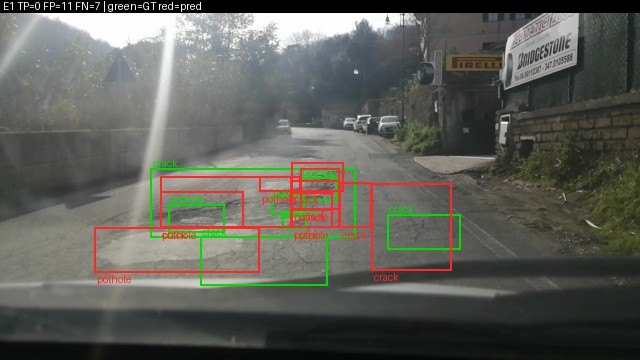

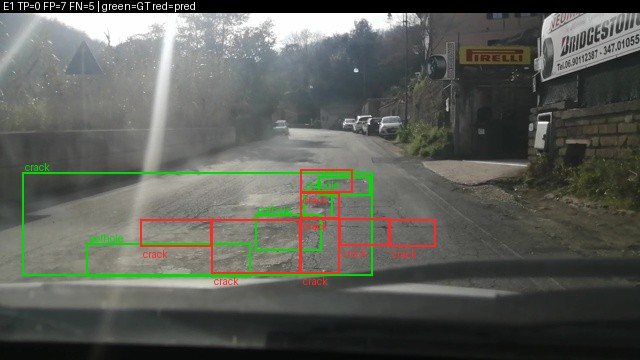

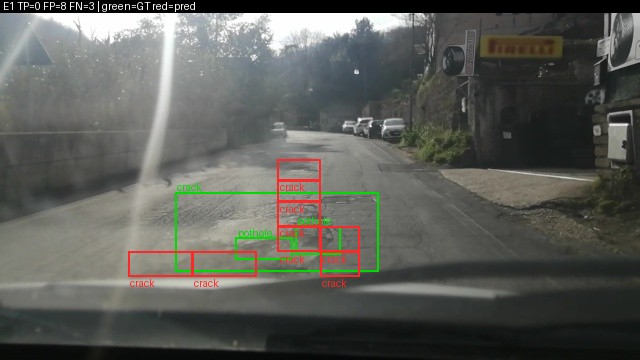

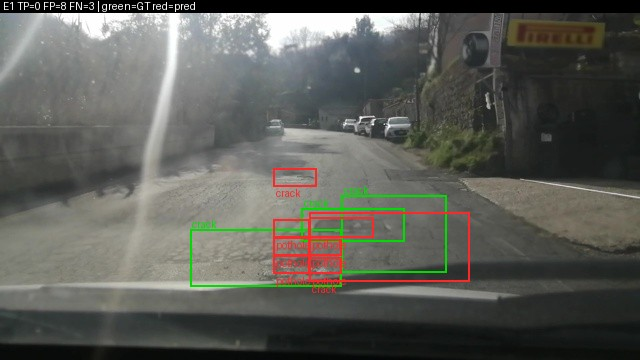

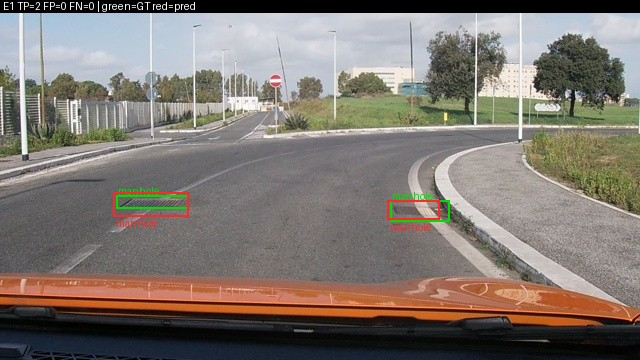

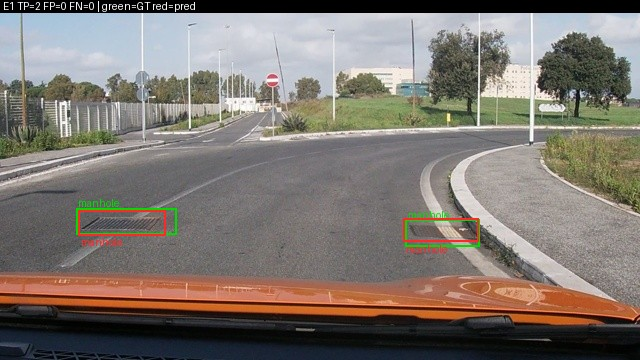

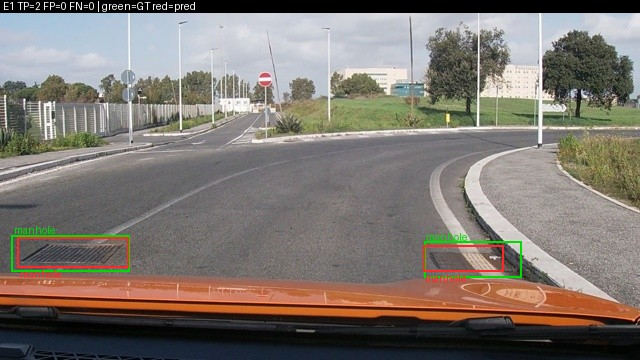

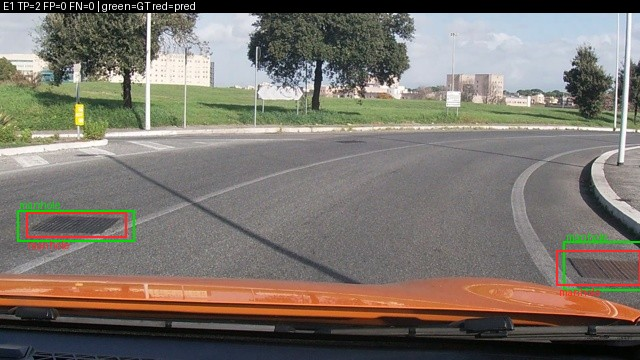

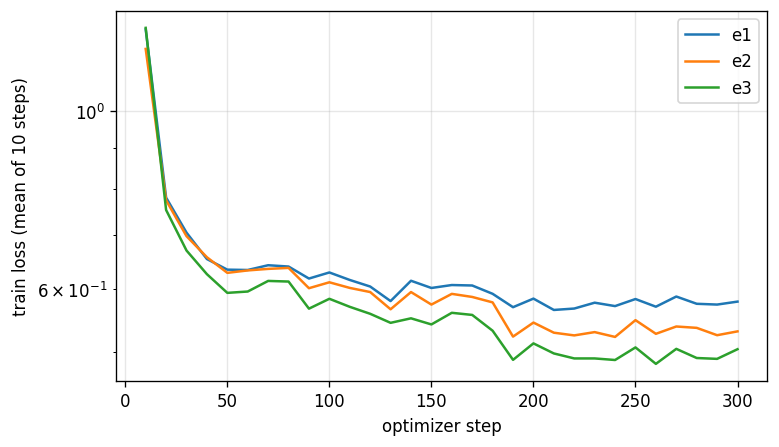

In [20]:
# Ảnh minh hoạ: 4 ảnh đúng hết + 4 ảnh sai nhiều nhất cho E0 và E1 (xanh = nhãn đúng, đỏ = dự đoán)
from IPython.display import Image as ShowImage, display

!python -m d10.viz --pred work/e0.jsonl --name E0
!python -m d10.viz --pred work/e1.jsonl --name E1 --loss
for f in sorted(glob.glob("report/figures/E1_*.jpg")):
    display(ShowImage(f))
display(ShowImage("report/figures/loss.png"))

## 8. E4 (ablation tự chọn) và E5 (tuỳ chọn, GRPO)

In [21]:
# E4 = data_size: lấy setup F1 cao nhất trong E1-E3, CHỈ đổi số ảnh train (10% so với 100%).
# 100% chính là lần chạy gốc, nên chỉ cần huấn luyện thêm một lần.
!python -m d10.pipeline e4
assert _exit_code == 0, "E4 lỗi"


===== E4 =====
base setup: e3 (F1 {'e1': 0.26343154246100514, 'e2': 0.3039301310043668, 'e3': 0.42124212421242124})

$ /usr/bin/python3 -m d10.train --config configs/e3.yaml --out work/runs/e4_data_size_0.1 --train-fraction 0.1 --name e4_data_size_0.1
train images: 142/1422
Loading weights: 100%|████████████████████████| 713/713 [00:07<00:00, 96.12it/s]
note: Found an incompatible version of torchao. Found version 0.10.0, but only versions above 0.16.0 are supported; ignoring torchao
LoRA modules: 348 | trainable params: 148,426,752 (LoRA 39,321,600 + projector 109,105,152)
[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.
{"step": 10, "loss": 1.274, "lr": 0.00014666666666666666, "minutes": 1.68, "vram_gb": 7.5}
{"step": 20, "loss": 0.7181, "lr": 0.00019984815164333163, "minutes": 3.39, "vram_gb": 7.7}
{"step": 30, "loss": 0.6341, "lr": 0.00019863613034027224, "minutes": 5.08, "vram_gb": 7.7}
{"step": 40, "loss": 0.5738, "lr": 0.00

In [22]:
# E5 (bonus): GRPO với reward IoU, khởi tạo từ adapter tốt nhất. Lỗi ở đây không chặn phần còn lại.
if RUN_E5:
    print(inspect.getsource(__import__("d10.reward", fromlist=["reward"]).reward))
    !python -m d10.pipeline e5
    print("E5 exit code:", _exit_code)

In [23]:
!python -m d10.summary
!python -m d10.viz --loss
if os.path.exists("work/e5.jsonl"):
    !python -m d10.viz --pred work/e5.jsonl --name E5
# REPORT.md chưa điền và số commit sẽ còn FAIL ở đây; các mục evidence phải PASS.
!python scripts/check_submission.py

## Kết quả trên test (từ report/evidence)

| Mã | Tham số huấn luyện | VRAM đỉnh (GB) | Phút | valid | P | R | F1 | CI95 | FP/ảnh | mean IoU | F1 pothole | F1 crack | F1 manhole |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| e0 | 0 |  |  | 0.942 | 0.094 | 0.065 | 0.077 | 0.055–0.103 | 1.18 | 0.619 | 0.112 | 0.021 | 0.172 |
| e1 | 33,030,144 | 6.38 | 42.34 | 1.000 | 0.266 | 0.261 | 0.263 | 0.228–0.304 | 1.35 | 0.689 | 0.148 | 0.190 | 0.545 |
| e2 | 142,135,296 | 8.07 | 42.92 | 1.000 | 0.310 | 0.298 | 0.304 | 0.269–0.340 | 1.25 | 0.680 | 0.172 | 0.226 | 0.592 |
| e3 | 148,426,752 | 8.25 | 50.94 | 0.997 | 0.443 | 0.401 | 0.421 | 0.378–0.465 | 0.95 | 0.698 | 0.288 | 0.327 | 0.717 |
| e4_data_size_0.1 | 148,426,752 | 7.7 | 50.47 | 1.000 | 0.270 | 0.302 | 0.285 | 0.249–0.321 | 1.53 | 0.675 | 0.161 | 0.227 | 0.546 |
| e4_data_size_1.0 | 148,426,752 | 8.25 | 50.94 | 0.997 | 0.443 | 0.401 | 0.421 | 0.378–0.465 | 0.95 | 0.698 | 0.288 | 0.327 | 0.717 |

## Thống kê output thô (từ r

In [24]:
# Đóng gói kết quả để tải về: report/ (evidence, logs, predictions, figures, summary.md)
# và data/splits/meta.json (chỉ để check_submission.py đối chiếu ở máy; data/ không được commit).
import zipfile
from pathlib import Path

OUT = "/kaggle/working/day10_results.zip"
with zipfile.ZipFile(OUT, "w", zipfile.ZIP_DEFLATED) as z:
    for p in sorted(Path("report").rglob("*")):
        if p.is_file():
            z.write(p)
    z.write("data/splits/meta.json")
print(OUT, f"{os.path.getsize(OUT) / 1e6:.1f} MB")
!ls -la report/evidence

/kaggle/working/day10_results.zip 1.2 MB
total 32
drwxr-xr-x 2 root root 4096 Oct 13 15:00 .
drwxr-xr-x 6 root root 4096 Oct 13 13:58 ..
-rw-r--r-- 1 root root 1222 Oct 13 11:07 e0.json
-rw-r--r-- 1 root root 1317 Oct 13 13:36 e1.json
-rw-r--r-- 1 root root 1316 Oct 13 13:46 e2.json
-rw-r--r-- 1 root root 1330 Oct 13 13:58 e3.json
-rw-r--r-- 1 root root 1405 Oct 13 15:00 e4_data_size_0.1.json
-rw-r--r-- 1 root root 1418 Oct 13 15:00 e4_data_size_1.0.json
-rw-r--r-- 1 root root    0 Oct 13 10:46 .gitkeep
